# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Deborah Villicaña Prieto  
**Grupo:** ISSC 512  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler 
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ruta = ("../data/raw/nyc_taxi_examen.csv")
df = pd.read_csv(ruta)
df.shape
df.head(5)


,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,...,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,...,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,...,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,...,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,...,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


In [50]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2427612 entries, 0 to 2427611
Data columns (total 21 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Unnamed: 0             int64  
 1   VendorID               int64  
 2   tpep_pickup_datetime   str    
 3   tpep_dropoff_datetime  str    
 4   passenger_count        float64
 5   trip_distance          float64
 6   RatecodeID             float64
 7   PULocationID           float64
 8   DOLocationID           float64
 9   payment_type           str    
 10  fare_amount            float64
 11  extra                  float64
 12  mta_tax                float64
 13  tip_amount             float64
 14  tolls_amount           float64
 15  improvement_surcharge  float64
 16  total_amount           float64
 17  congestion_surcharge   float64
 18  Airport_fee            float64
 19  cbd_congestion_fee     float64
 20  trip_duration          float64
dtypes: float64(16), int64(2), str(3)
memory usage: 388.9 MB


In [51]:
df.describe()

,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.213806e+06,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,7.007914e+05,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,0.000000e+00,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,6.069028e+05,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,1.213806e+06,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,1.820708e+06,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,2.427611e+06,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03


In [52]:
df['payment_type'].unique()

<StringArray>
['Credit card', 'Cash', nan, 'Dispute', 'No charge']
Length: 5, dtype: str

## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [53]:
#Conteo de datos en el dataset antes de limpiar
df.shape


(2427612, 21)

In [54]:
df.isnull().sum()

Unnamed: 0                   0
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

In [68]:
df.duplicated().sum()

np.int64(0)

In [55]:
dfNoNull = df.dropna().copy()
dfNoDupli = dfNoNull.drop_duplicates().copy()
dfV2 = dfNoDupli
dfV2distance = dfV2[dfV2['trip_distance']>0].copy()
dfv2passCount = dfV2distance[(dfV2distance['passenger_count'] > 0) & (dfV2distance['passenger_count'] < 100)].copy()
dfv2fareAmount = dfv2passCount[(dfv2passCount['fare_amount'] > 0) & (dfv2passCount['fare_amount'] < 10000)].copy()
dfv2tripDuration = dfv2fareAmount[dfv2fareAmount['trip_duration'] > 0]
df_limpio = dfv2tripDuration.copy()
df_limpio.shape





(2107024, 21)

## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [56]:
df_cash = df_limpio[df_limpio['payment_type'] == 'Cash']
#df_cash.head(5)

X = df_cash[["passenger_count", "trip_distance"]].copy()
X.shape

(283537, 2)

In [66]:
X.describe()

,passenger_count,trip_distance
count,283537.000000,283537.000000
mean,1.343786,3.842333
std,0.758948,6.210980
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


In [58]:
X.tail(10)

,passenger_count,trip_distance
2427512,1.0,0.79
2427515,1.0,36.83
2427517,1.0,1.89
2427520,1.0,1.99
2427537,2.0,1.40
2427584,1.0,10.68
2427589,1.0,1.57
2427597,2.0,0.83
2427600,1.0,0.90
2427610,1.0,7.40


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [59]:
X_log = np.log1p(X)
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)

print("Medias:", X_escalado.mean(axis=0).round(4))
print("Desviaciones:", X_escalado.std(axis=0).round(4))

Medias: [-0.  0.]
Desviaciones: [1. 1.]


In [69]:
pd.DataFrame(X_escalado, columns=["passenger_count", "trip_distance"]).describe()

,passenger_count,trip_distance
count,2.835370e+05,2.835370e+05
mean,-3.432213e-16,1.395339e-16
std,1.000002e+00,1.000002e+00
min,-4.859139e-01,-1.592418e+00
25%,-4.859139e-01,-7.508485e-01
50%,-4.859139e-01,-3.042034e-01
75%,-4.859139e-01,5.965843e-01
max,4.520428e+00,8.129834e+00


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [60]:
valores_k = range(2, 7)

inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)

    silueta = silhouette_score(
        X_escalado,
        etiquetas,
        sample_size=5000,
        random_state=42
    )
    siluetas.append(silueta)

In [61]:
tabla_resultados = pd.DataFrame({
    "k": list(valores_k),
    "Inercia": inercias,
    "Silueta" : siluetas
})

display(tabla_resultados)

,k,Inercia,Silueta
0,2,326248.007285,0.550175
1,3,161175.263705,0.592143
2,4,115676.032071,0.608636
3,5,87354.812934,0.615501
4,6,61467.324771,0.552885


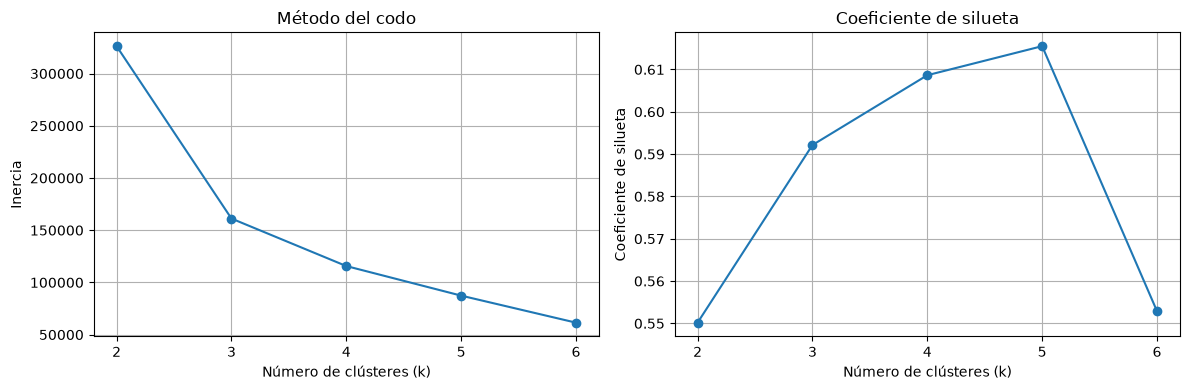

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfica 1: Método del codo
axes[0].plot(list(valores_k), inercias, marker='o')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clústeres (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_xticks(list(valores_k))
axes[0].grid(True)

# Gráfica 2: Coeficiente de silueta
axes[1].plot(list(valores_k), siluetas, marker='o')
axes[1].set_title('Coeficiente de silueta')
axes[1].set_xlabel('Número de clústeres (k)')
axes[1].set_ylabel('Coeficiente de silueta')
axes[1].set_xticks(list(valores_k))
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

In [63]:
k_final = 4

modelo_final = KMeans(n_clusters=k_final, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)

print("k elegido:", k_final)
print("Inercia del modelo final:", round(modelo_final.inertia_, 2))
print("Viajes por clúster:")
print(pd.Series(etiquetas).value_counts().sort_index())

k elegido: 4
Inercia del modelo final: 115676.03
Viajes por clúster:
0    161122
1     60344
2     43146
3     18925
Name: count, dtype: int64


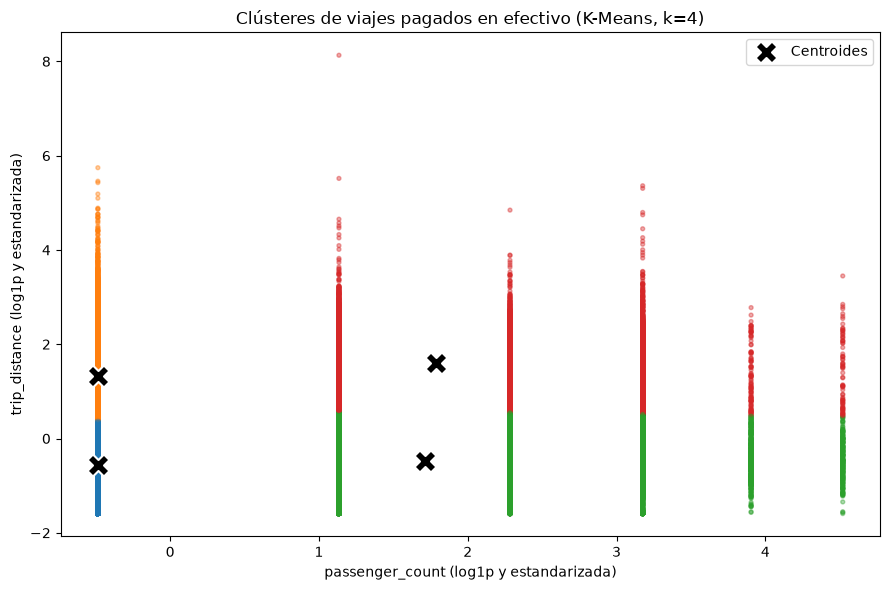

In [64]:
plt.figure(figsize=(9, 6))

plt.scatter(X_escalado[:, 0], X_escalado[:, 1],
            c=etiquetas, cmap="tab10", s=8, alpha=0.4, vmin=-0.5, vmax=9.5)

plt.scatter(modelo_final.cluster_centers_[:, 0], modelo_final.cluster_centers_[:, 1],
            color="black", marker="X", s=250, edgecolor="white", linewidth=1.5,
            label="Centroides")

plt.title("Clústeres de viajes pagados en efectivo (K-Means, k=4)")
plt.xlabel("passenger_count (log1p y estandarizada)")
plt.ylabel("trip_distance (log1p y estandarizada)")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [65]:
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

resumen = df_resultado.groupby("cluster").agg(
    Viajes=("passenger_count", "size"),
    Pasajeros_media=("passenger_count", "mean"),
    Pasajeros_mediana=("passenger_count", "median"),
    Distancia_media=("trip_distance", "mean"),
    Distancia_mediana=("trip_distance", "median")
)

display(resumen.round(2))

,Viajes,Pasajeros_media,Pasajeros_mediana,Distancia_media,Distancia_mediana
cluster,,,,,
0,161122,1.00,1.0,1.36,1.20
1,60344,1.00,1.0,9.54,7.95
2,43146,2.55,2.0,1.53,1.30
3,18925,2.62,2.0,12.08,10.37


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí k = 4 porque es  mucho más notorio que la incercia baja al pasar de 2 a 3 grupos, y todavía más al pasar a 4. Después de ahí comienza a estabilizarse un poco entonces las mejores son más chicas. Por lo tanto, el codo queda entre 3 y 4. En la silueta, k = 4 (0.6086) y k = 5 (0.6155) salen mejor que k = 3 (0.5921) y k = 6 (0.5529). k = 5 gana por poquito, pero la diferencia es de solo 0.007 y se calculó con una muestra de 5000 viajes, así que no es una ventaja real. Decidí quedarme con k 4, ya que además de que la diferencia entre 4 y 5 es mínima, al seleccionar k = 4 es más fácil interpretar los resultados, ya que separa los viajes de 1 pasajero y de 2 o más, y cada uno en distancia corta y larga.


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** 
Clúster 0, “Viajes cortos individuales” (161,122 viajes, 56.8%): van con 1 pasajero (media y mediana de 1.00) y recorren poca distancia (media 1.36 mi, mediana 1.20 mi). Es el grupo más grande.

Clúster 1, “Viajes largos individuales” (60,344 viajes, 21.3%): también con 1 pasajero, pero con distancias largas (media 9.54 mi, mediana 7.95 mi).

Clúster 2, “Viajes cortos en grupo” (43,146 viajes, 15.2%): llevan 2 o más pasajeros (media 2.55, mediana 2.0) y viajes cortos (media 1.53 mi, mediana 1.30 mi).

Clúster 3, “Viajes largos en grupo” (18,925 viajes, 6.7%): también 2 o más pasajeros (media 2.62, mediana 2.0) y son los viajes más largos (media 12.08 mi, mediana 10.37 mi). Es el grupo más chico.


**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:** Los grupos con menos pasajeros son el 0 y el 1 (1.00 en promedio) y los que más llevan son el 2 y el 3 (2.55 y 2.62). Los viajes de una sola persona son la gran mayoría: 221,466 viajes, cerca del 78%, contra unos 62,071 (22%) con 2 o más pasajeros. Dentro del mismo tipo de distancia, los grupos con más pasajeros hacen viajes un poco más largos: en los cortos la mediana es 1.30 mi contra 1.20 mi, y en los largos 10.37 mi contra 7.95 mi. Aun así, el número de pasajeros casi no cambia entre un viaje corto y uno largo (1.00 contra 1.00, y 2.55 contra 2.62).


**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:** No siempre. Los clústeres muestran viajes largos con un solo pasajero (clúster 1, mediana de 7.95 mi) y viajes cortos con varios pasajeros (clúster 2, mediana de 1.30 mi). Además, los viajes cortos son la mayoría en los dos niveles de pasajeros: los clústeres 0 y 2 suman cerca del 72% de los viajes. Sí se ve una tendencia ligera, porque los grupos con más pasajeros tienen medianas de distancia un poco mayores, pero es solo eso, una tendencia y no una regla. Dos viajes con los mismos pasajeros pueden tener distancias muy diferentes, así que el número de pasajeros por sí solo no determina qué tan largo es el viaje.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**